# Lab 05 - Task 2: Is Linear Regression Appropriate for Household Electricity Consumption?

**Course:** AL3002 (Machine Learning Lab) | **Instructor:** Muhammad Khalid

**Question:** Using the dataset of monthly household electricity consumption, decide whether Linear Regression is suitable by checking its assumptions: linearity, independence, homoscedasticity, normality of residuals, no (perfect) multicollinearity, no autocorrelation and additivity.

**Dataset note:** the file used here (`Household_energy_unit_data.csv`) has 1,000 households. The target `units` is monthly consumption in kWh. The task text mentions residents, income and house age; in this file the matching columns are `num_people` (residents) and `housearea` (size of the house). There is no income or house-age column, so the other household attributes (rooms, children, AC, TV, flat, urban) are used as predictors.

## 1. Load and Review the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style='whitegrid')

raw = pd.read_csv('Household_energy_unit_data.csv')
print('Shape:', raw.shape)
raw.head()

Shape: (1000, 9)


,num_rooms,num_people,housearea,is_ac,is_tv,is_flat,num_children,is_urban,units
0,3,3,742.57,1,1,1,2,0,134.731117
1,1,5,952.99,0,1,0,1,1,125.315527
2,3,1,761.44,1,1,1,0,0,123.047874
3,0,5,861.32,1,1,0,0,0,80.046162
4,1,8,731.61,0,1,0,2,1,128.429094


In [2]:
print('Missing values:', int(raw.isnull().sum().sum()), '| Duplicate rows:', int(raw.duplicated().sum()))
raw.describe().T.round(2)

Missing values: 0 | Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
num_rooms,1000.0,1.96,1.03,-1.00,1.00,2.00,3.00,5.00
num_people,1000.0,4.90,2.01,-1.00,4.00,5.00,6.00,11.00
housearea,1000.0,794.70,147.77,244.40,691.04,789.97,892.96,1189.12
is_ac,1000.0,0.38,0.48,0.00,0.00,0.00,1.00,1.00
is_tv,1000.0,0.80,0.40,0.00,1.00,1.00,1.00,1.00
is_flat,1000.0,0.48,0.50,0.00,0.00,0.00,1.00,1.00
num_children,1000.0,1.08,0.93,0.00,0.00,1.00,2.00,4.00
is_urban,1000.0,0.61,0.49,0.00,0.00,1.00,1.00,1.00
units,1000.0,123.60,27.11,21.12,109.16,126.33,141.82,204.19


**Observation:** `num_rooms` and `num_people` have a minimum of -1, and `num_people` has zeros. A household cannot have a negative number of rooms or people, or zero residents, so these are data-entry errors.

### Data quality: remove impossible values

In [3]:
invalid = (raw['num_rooms'] < 0) | (raw['num_people'] <= 0)
print('Rows with negative rooms           :', int((raw['num_rooms'] < 0).sum()))
print('Rows with negative or zero residents:', int((raw['num_people'] <= 0).sum()))
print('Total rows removed                  :', int(invalid.sum()))

df = raw[~invalid].reset_index(drop=True)
print('Clean shape:', df.shape)

Rows with negative rooms           : 5
Rows with negative or zero residents: 17
Total rows removed                  : 22
Clean shape: (978, 9)


Rows with `num_rooms = 0` are kept (they can be one-room homes such as studios).

## 2. Quick EDA

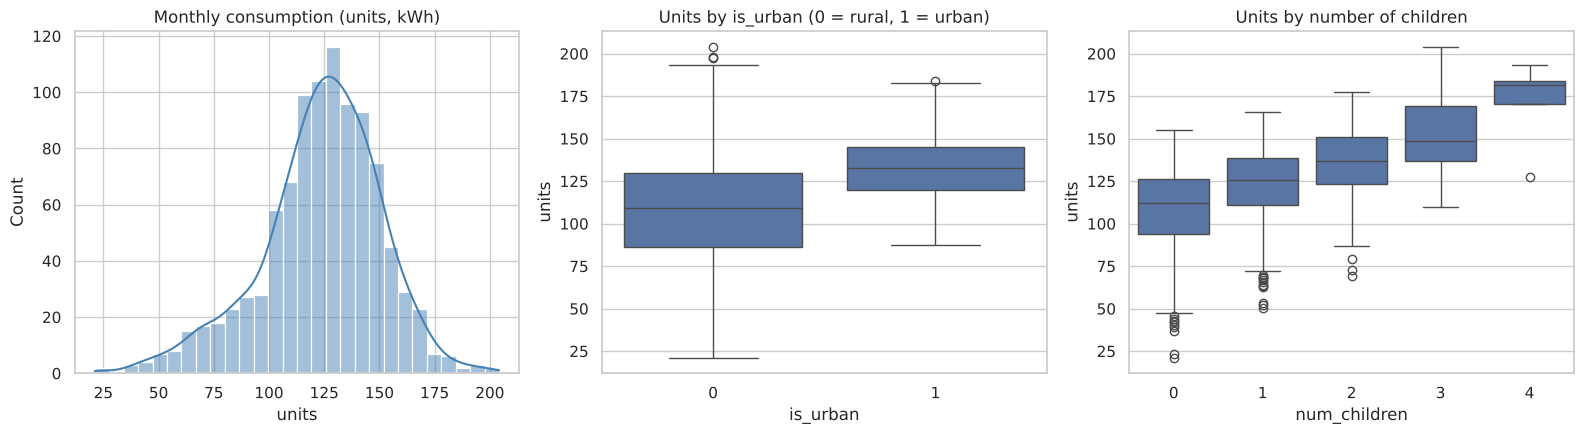

units           1.000
num_children    0.509
is_ac           0.453
is_urban        0.431
is_tv           0.207
is_flat         0.168
housearea       0.094
num_people      0.072
num_rooms      -0.017
Name: units, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df['units'], kde=True, ax=axes[0], color='steelblue'); axes[0].set_title('Monthly consumption (units, kWh)')
sns.boxplot(x='is_urban', y='units', data=df, ax=axes[1]); axes[1].set_title('Units by is_urban (0 = rural, 1 = urban)')
sns.boxplot(x='num_children', y='units', data=df, ax=axes[2]); axes[2].set_title('Units by number of children')
plt.tight_layout(); plt.show()

print(df.corr()['units'].sort_values(ascending=False).round(3))

**Observation:** consumption rises clearly with children, AC and urban location. Rural homes are far more spread out than urban homes, which already hints at unequal variance. `num_people` and `housearea` show almost no linear correlation with `units`.

## 3. Fit a Baseline Linear Regression (all features)

In [5]:
features = ['num_rooms', 'num_people', 'housearea', 'is_ac', 'is_tv', 'is_flat', 'num_children', 'is_urban']
X = sm.add_constant(df[features])
y = df['units']

base = sm.OLS(y, X).fit()
print(base.summary().tables[1])
print('\nR2 = %.3f | Adjusted R2 = %.3f' % (base.rsquared, base.rsquared_adj))

resid = base.resid
fitted = base.fittedvalues
results = []   # collects one row per assumption for the summary table

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           59.1883      2.929     20.207      0.000      53.440      64.936
num_rooms        0.2341      0.425      0.551      0.582      -0.600       1.068
num_people       0.7105      0.225      3.153      0.002       0.268       1.153
housearea        0.0049      0.003      1.673      0.095      -0.001       0.011
is_ac           27.1945      0.887     30.654      0.000      25.454      28.935
is_tv           12.3266      1.072     11.499      0.000      10.223      14.430
is_flat          9.7659      0.858     11.376      0.000       8.081      11.451
num_children    15.3170      0.461     33.190      0.000      14.411      16.223
is_urban        25.1776      0.878     28.682      0.000      23.455      26.900

R2 = 0.758 | Adjusted R2 = 0.756


The baseline fits reasonably well (R2 about 0.76), but a good R2 does not prove the assumptions hold. Each assumption is tested below.

## 4. Assumption Checks

### 4.1 Linearity

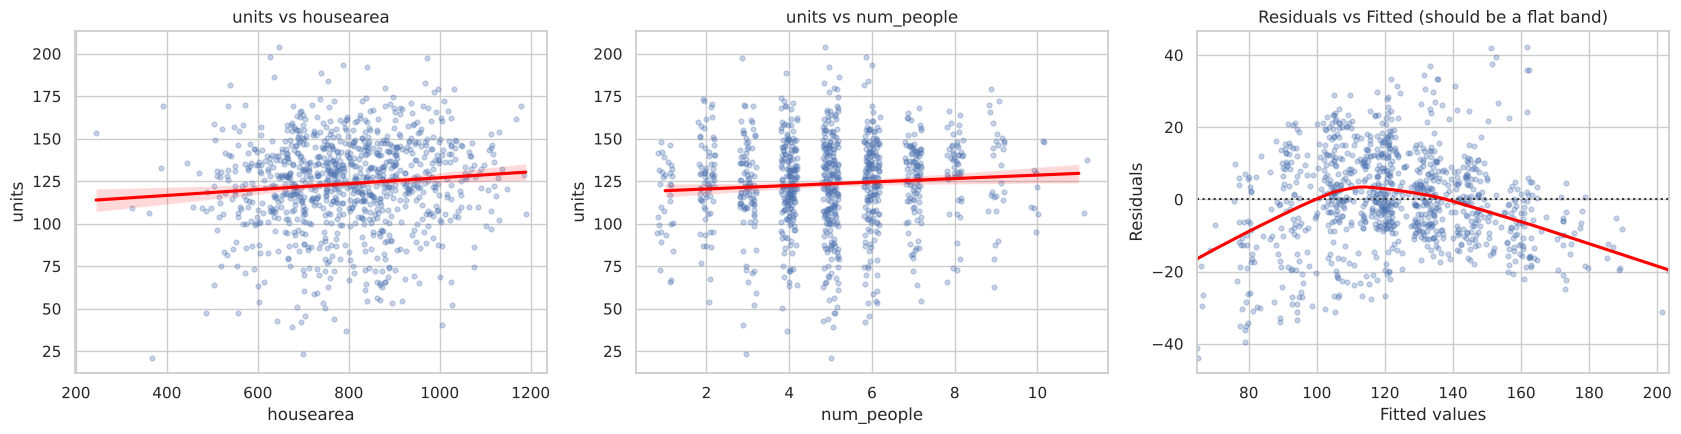

Ramsey RESET test: F = 146.60, p = 1.6e-31


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x='housearea', y='units', data=df, ax=axes[0], scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'})
axes[0].set_title('units vs housearea')
sns.regplot(x='num_people', y='units', data=df, ax=axes[1], x_jitter=0.2, scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'})
axes[1].set_title('units vs num_people')
sns.residplot(x=fitted, y=resid, lowess=True, ax=axes[2], scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'})
axes[2].set_xlabel('Fitted values'); axes[2].set_ylabel('Residuals'); axes[2].set_title('Residuals vs Fitted (should be a flat band)')
plt.tight_layout(); plt.show()

reset = linear_reset(base, power=2, use_f=True)
print("Ramsey RESET test: F = %.2f, p = %.3g" % (reset.fvalue, reset.pvalue))
results.append(['Linearity', 'Ramsey RESET', round(float(reset.fvalue), 2), float(reset.pvalue), 'FAIL' if reset.pvalue < 0.05 else 'PASS'])

**Result:** RESET rejects the linear specification (p is far below 0.05). The model is missing structure (shown in 4.6: the effect of AC and children depends on urban/rural).

### 4.2 Independence / No autocorrelation

Durbin-Watson = 1.945  (about 2 means no autocorrelation)
Lag-1 autocorrelation of residuals = 0.026


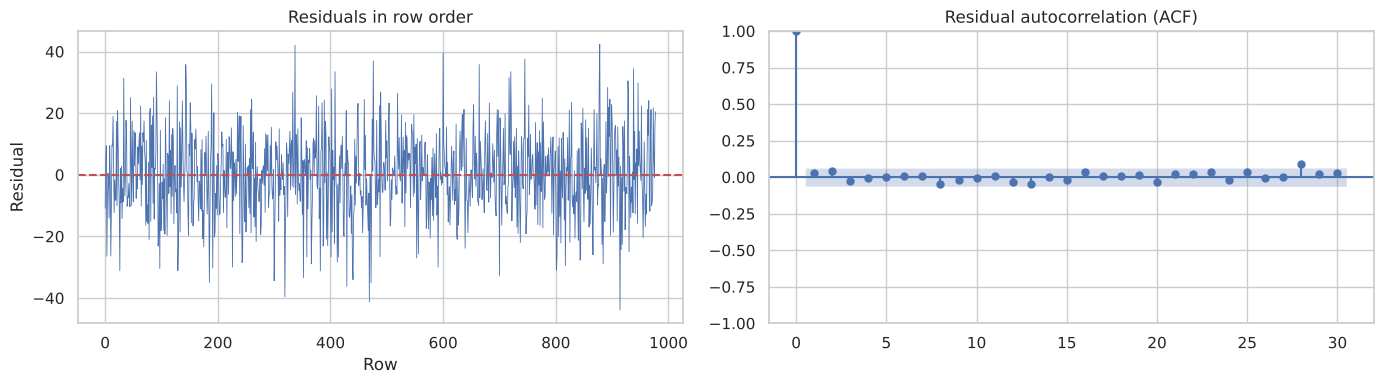

In [7]:
dw = durbin_watson(resid)
lag1 = pd.Series(resid.values).autocorr(1)
print('Durbin-Watson = %.3f  (about 2 means no autocorrelation)' % dw)
print('Lag-1 autocorrelation of residuals = %.3f' % lag1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(resid.values, lw=0.6); axes[0].axhline(0, color='r', ls='--')
axes[0].set_title('Residuals in row order'); axes[0].set_xlabel('Row'); axes[0].set_ylabel('Residual')
sm.graphics.tsa.plot_acf(resid, lags=30, ax=axes[1]); axes[1].set_title('Residual autocorrelation (ACF)')
plt.tight_layout(); plt.show()

results.append(['Independence / no autocorrelation', 'Durbin-Watson', round(float(dw), 3), np.nan, 'PASS' if 1.5 < dw < 2.5 else 'FAIL'])

**Result:** Durbin-Watson is close to 2 and the ACF shows no pattern, so the errors look independent. Each row is a different household, so independence is also reasonable from the way the data was collected.

### 4.3 Homoscedasticity (constant variance)

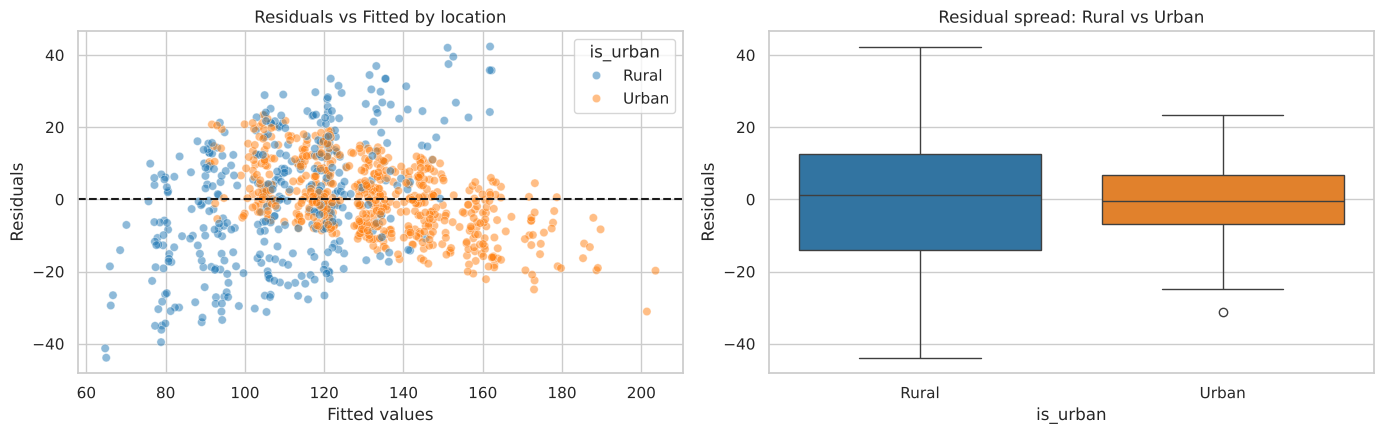

Breusch-Pagan: LM = 162.92, p = 3.92e-31
Levene test (rural vs urban residual variance): stat = 186.68, p = 5.12e-39
Residual std  -> rural: 17.64 | urban: 9.54


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(x=fitted, y=resid, hue=df['is_urban'].map({0: 'Rural', 1: 'Urban'}), hue_order=['Rural', 'Urban'],
                palette={'Rural': 'tab:blue', 'Urban': 'tab:orange'}, alpha=0.5, ax=axes[0])
axes[0].axhline(0, color='k', ls='--'); axes[0].set_xlabel('Fitted values'); axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted by location')
sns.boxplot(x=df['is_urban'].map({0: 'Rural', 1: 'Urban'}), y=resid, order=['Rural', 'Urban'],
            palette={'Rural': 'tab:blue', 'Urban': 'tab:orange'}, hue=df['is_urban'].map({0: 'Rural', 1: 'Urban'}),
            legend=False, ax=axes[1]); axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual spread: Rural vs Urban')
plt.tight_layout(); plt.show()

bp = het_breuschpagan(resid, X)
lev = stats.levene(resid[df['is_urban'] == 0], resid[df['is_urban'] == 1])
print('Breusch-Pagan: LM = %.2f, p = %.3g' % (bp[0], bp[1]))
print('Levene test (rural vs urban residual variance): stat = %.2f, p = %.3g' % (lev.statistic, lev.pvalue))
print('Residual std  -> rural: %.2f | urban: %.2f' % (resid[df['is_urban'] == 0].std(), resid[df['is_urban'] == 1].std()))
results.append(['Homoscedasticity', 'Breusch-Pagan', round(float(bp[0]), 2), float(bp[1]), 'FAIL' if bp[1] < 0.05 else 'PASS'])

**Result:** violated. Residuals for rural households are about twice as spread out as for urban households, and both tests reject constant variance.

### 4.4 Normality of residuals

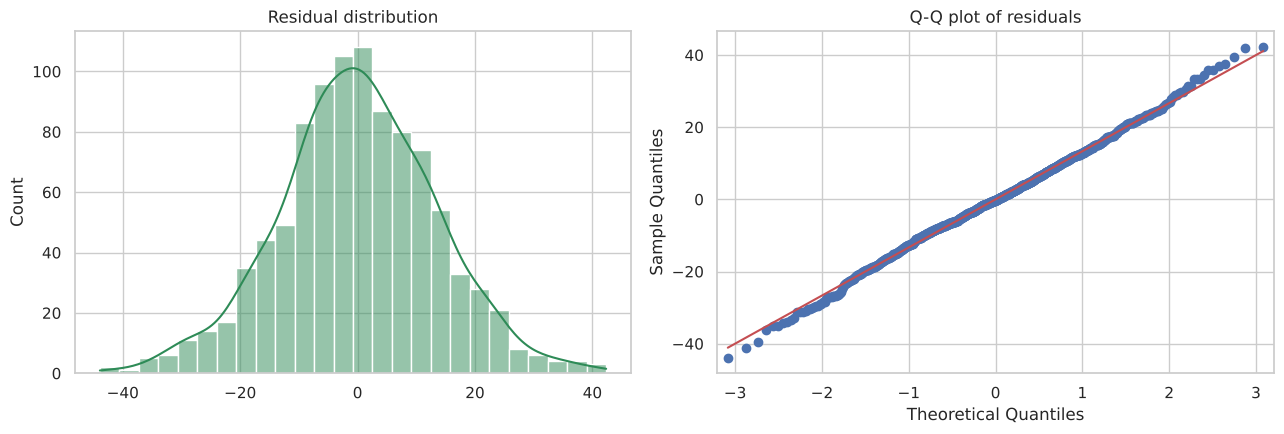

Shapiro-Wilk: W = 0.9978, p = 0.234
Skewness = -0.013 | Excess kurtosis = 0.266


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(resid, kde=True, ax=axes[0], color='seagreen'); axes[0].set_title('Residual distribution')
sm.qqplot(resid, line='s', ax=axes[1]); axes[1].set_title('Q-Q plot of residuals')
plt.tight_layout(); plt.show()

sh = stats.shapiro(resid)
print('Shapiro-Wilk: W = %.4f, p = %.3f' % (sh.statistic, sh.pvalue))
print('Skewness = %.3f | Excess kurtosis = %.3f' % (stats.skew(resid), stats.kurtosis(resid)))
results.append(['Normality of residuals', 'Shapiro-Wilk', round(float(sh.statistic), 4), float(sh.pvalue), 'PASS' if sh.pvalue > 0.05 else 'FAIL'])

**Result:** satisfied. The histogram is bell-shaped, the Q-Q points follow the line, and Shapiro-Wilk does not reject normality.

### 4.5 No (perfect) multicollinearity

,feature,VIF
0,num_rooms,1.01
1,num_people,1.00
2,housearea,1.01
3,is_ac,1.01
4,is_tv,1.01
5,is_flat,1.00
6,num_children,1.01
7,is_urban,1.00


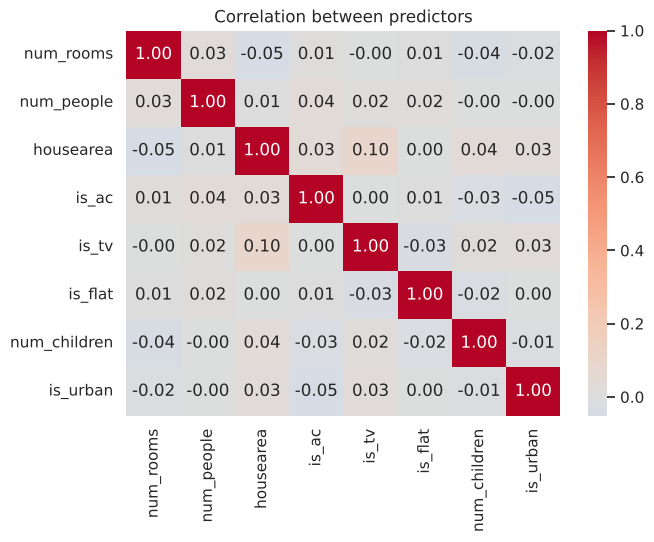

In [10]:
vif = pd.DataFrame({
    'feature': features,
    'VIF': [variance_inflation_factor(X.values, i + 1) for i in range(len(features))]
}).round(2)
display(vif)

plt.figure(figsize=(7, 5))
sns.heatmap(df[features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between predictors'); plt.show()

results.append(['No multicollinearity', 'Max VIF', round(float(vif['VIF'].max()), 2), np.nan, 'PASS' if vif['VIF'].max() < 5 else 'FAIL'])

**Result:** satisfied. Every VIF is about 1 (the usual warning level is 5 to 10), so the predictors are not related to each other.

### 4.6 Additivity (effects do not depend on other variables)

,interaction,coefficient,p-value,R2 with term,significant (p<0.05)
0,is_urban x is_ac,-16.4589,0.0000,0.7786,True
1,is_urban x num_children,-10.4016,0.0000,0.7884,True
2,is_urban x is_flat,-8.5324,0.0000,0.7637,True
3,is_urban x housearea,-0.0025,0.6784,0.7579,False
4,is_ac x num_children,1.0484,0.2696,0.7582,False


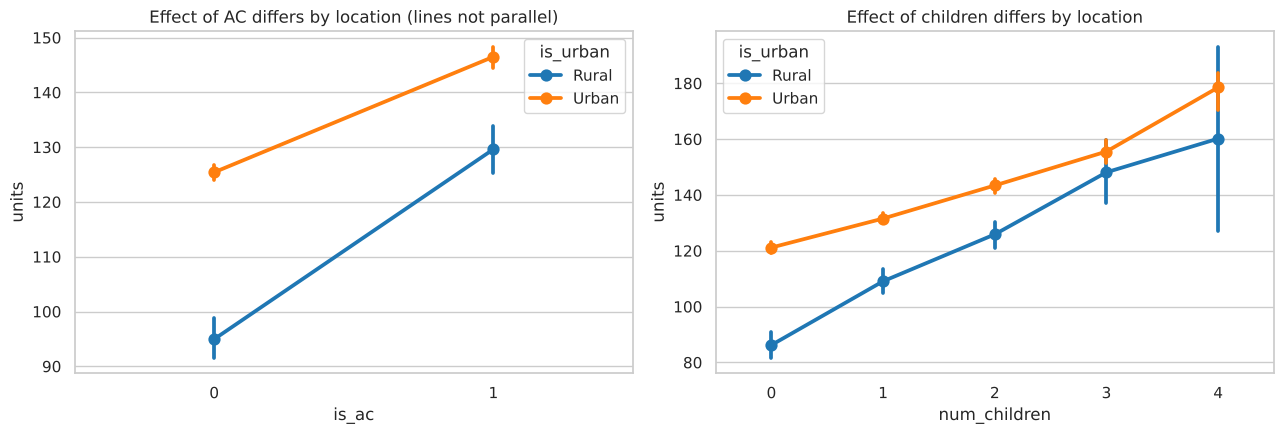

Coefficients fitted separately for rural and urban households:


,rural,urban
const,42.04,93.71
num_rooms,-0.01,-0.04
num_people,0.88,0.77
housearea,0.00,0.01
is_ac,38.11,20.62
is_tv,17.47,9.69
is_flat,16.33,6.63
num_children,22.17,11.19


In [11]:
pairs = [('is_urban', 'is_ac'), ('is_urban', 'num_children'), ('is_urban', 'is_flat'),
         ('is_urban', 'housearea'), ('is_ac', 'num_children')]
rows = []
for a, b in pairs:
    X_int = X.copy()
    X_int[a + '*' + b] = df[a] * df[b]
    m_int = sm.OLS(y, X_int).fit()
    rows.append([a + ' x ' + b, m_int.params[a + '*' + b], m_int.pvalues[a + '*' + b], m_int.rsquared])
inter = pd.DataFrame(rows, columns=['interaction', 'coefficient', 'p-value', 'R2 with term'])
inter['significant (p<0.05)'] = inter['p-value'] < 0.05
display(inter.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
loc = df['is_urban'].map({0: 'Rural', 1: 'Urban'})
pal = {'Rural': 'tab:blue', 'Urban': 'tab:orange'}
sns.pointplot(x='is_ac', y='units', hue=loc, hue_order=['Rural', 'Urban'], palette=pal, data=df, ax=axes[0])
axes[0].set_title('Effect of AC differs by location (lines not parallel)')
sns.pointplot(x='num_children', y='units', hue=loc, hue_order=['Rural', 'Urban'], palette=pal, data=df, ax=axes[1])
axes[1].set_title('Effect of children differs by location')
plt.tight_layout(); plt.show()

sub = []
for u, g in df.groupby('is_urban'):
    mm = sm.OLS(g['units'], sm.add_constant(g[[f for f in features if f != 'is_urban']])).fit()
    sub.append(pd.Series(mm.params, name='urban' if u == 1 else 'rural'))
print('Coefficients fitted separately for rural and urban households:')
display(pd.DataFrame(sub).round(2).T)

n_sig = int(inter.iloc[:3]['significant (p<0.05)'].sum())
results.append(['Additivity', 'Interaction F/t-tests', n_sig, float(inter['p-value'].min()), 'FAIL' if n_sig > 0 else 'PASS'])

**Result:** violated. An AC adds roughly 38 kWh in rural homes but about 21 kWh in urban homes, and each child adds about 22 kWh (rural) versus about 11 kWh (urban). A single set of coefficients cannot capture both groups. This is also the reason RESET failed.

## 5. Summary of Assumptions

In [12]:
summary = pd.DataFrame(results, columns=['Assumption', 'Test', 'Statistic', 'p-value', 'Result'])
summary['p-value'] = summary['p-value'].map(lambda p: '' if pd.isna(p) else ('%.2e' % p))
display(summary)

,Assumption,Test,Statistic,p-value,Result
0,Linearity,Ramsey RESET,146.6000,1.60e-31,FAIL
1,Independence / no autocorrelation,Durbin-Watson,1.9450,,PASS
2,Homoscedasticity,Breusch-Pagan,162.9200,3.92e-31,FAIL
3,Normality of residuals,Shapiro-Wilk,0.9978,2.34e-01,PASS
4,No multicollinearity,Max VIF,1.0100,,PASS
5,Additivity,Interaction F/t-tests,3.0000,3.58e-30,FAIL


## 6. Can the Problems Be Fixed? (supporting check)

In [13]:
# Add interactions with is_urban so the model can use different slopes for rural and urban homes
X2 = X.copy()
for c in ['num_rooms', 'num_people', 'housearea', 'is_ac', 'is_tv', 'is_flat', 'num_children']:
    X2['urban_x_' + c] = df['is_urban'] * df[c]
inter_model = sm.OLS(y, X2).fit()

# Weighted least squares: weight each group by the inverse of its residual variance
group_var = inter_model.resid.groupby(df['is_urban']).var()
weights = df['is_urban'].map(lambda u: 1 / group_var[u])
wls = sm.WLS(y, X2, weights=weights).fit()

# Test-set comparison with scikit-learn
def test_scores(frame):
    a, b, c, d = train_test_split(frame, y, test_size=0.2, random_state=42)
    p = LinearRegression().fit(a, c).predict(b)
    return r2_score(d, p), mean_absolute_error(d, p)

r2_b, mae_b = test_scores(df[features])
r2_i, mae_i = test_scores(X2.drop(columns='const'))

compare = pd.DataFrame({
    'Baseline (additive)': [base.rsquared_adj, linear_reset(base, power=2, use_f=True).pvalue, het_breuschpagan(base.resid, X)[1],
                            stats.shapiro(base.resid).pvalue, r2_b, mae_b],
    'With urban interactions': [inter_model.rsquared_adj, linear_reset(inter_model, power=2, use_f=True).pvalue,
                                het_breuschpagan(inter_model.resid, X2)[1], stats.shapiro(inter_model.resid).pvalue, r2_i, mae_i],
}, index=['Adjusted R2 (train)', 'RESET p-value (linearity)', 'Breusch-Pagan p-value', 'Shapiro p-value', 'Test R2', 'Test MAE (kWh)'])
display(compare.round(4))

wres = wls.resid * np.sqrt(weights)
print('WLS: standardised residual std -> rural %.2f | urban %.2f (equal variance after weighting)' %
      (wres[df['is_urban'] == 0].std(), wres[df['is_urban'] == 1].std()))

# Robust (HC3) standard errors on the baseline model
rob = sm.OLS(y, X).fit(cov_type='HC3')
print('\nStandard error of is_urban coefficient -> classical: %.3f | robust HC3: %.3f' % (base.bse['is_urban'], rob.bse['is_urban']))

,Baseline (additive),With urban interactions
Adjusted R2 (train),0.7559,0.8190
RESET p-value (linearity),0.0000,0.8667
Breusch-Pagan p-value,0.0000,0.0000
Shapiro p-value,0.2344,0.0034
Test R2,0.7345,0.8028
Test MAE (kWh),10.2717,9.4354


WLS: standardised residual std -> rural 1.00 | urban 1.00 (equal variance after weighting)

Standard error of is_urban coefficient -> classical: 0.878 | robust HC3: 0.984


Adding the urban interactions fixes the linearity/additivity problem (RESET p-value rises from almost 0 to well above 0.05) and improves test R2 and MAE. Unequal variance remains, so weighted least squares (or robust standard errors) is needed for trustworthy inference.

## 7. Decision and Justification

**Decision: plain (additive) Linear Regression is NOT appropriate for this dataset as it stands.**

| Assumption | Verdict | Evidence |
|---|---|---|
| Linearity | **Violated** | Ramsey RESET F = 146.6, p about 1.6e-31 |
| Additivity | **Violated** | is_urban x is_ac, is_urban x num_children and is_urban x is_flat are all significant; AC adds about 38 kWh (rural) vs 21 kWh (urban) |
| Homoscedasticity | **Violated** | Breusch-Pagan p about 3.9e-31; residual std 17.6 (rural) vs 9.5 (urban) |
| Independence / no autocorrelation | Satisfied | Durbin-Watson = 1.945, lag-1 autocorrelation = 0.026 |
| Normality of residuals | Satisfied | Shapiro-Wilk W = 0.9978, p = 0.234; symmetric Q-Q plot |
| No multicollinearity | Satisfied | all VIF about 1.0 |

**Why it matters:** the baseline R2 (0.76) looks good, but two core assumptions fail. Coefficients are forced to be the same for rural and urban homes, so predictions are biased for each group, and standard errors, t-tests and confidence intervals are unreliable because the variance is not constant.

**Data quality:** 22 rows with negative or zero rooms/residents were removed first. These are impossible values and would distort the fit.

**Recommended approach:** use Linear Regression only after adding `is_urban` interaction terms (or fitting separate models for rural and urban homes) and using weighted least squares or robust standard errors. With the interactions, adjusted R2 rises from 0.756 to 0.819 and test R2 from 0.734 to 0.803 (MAE 10.27 to 9.44 kWh), and linearity is restored (RESET p about 0.87). Heteroscedasticity still needs the weighting step, and residual normality becomes marginal after adding interactions (Shapiro p about 0.003), so check the Q-Q plot if you rely on confidence intervals.